# Portfolio Allocation Project — Part 2: Minimum-Variance Portfolio

**Goal:** estimate $\Sigma$ from an estimation period, compute the minimum-variance weights

$$\hat{\mathbf a} = \frac{\hat\Sigma^{-1}\boldsymbol\iota}{\boldsymbol\iota^\top\hat\Sigma^{-1}\boldsymbol\iota}$$

and check how they perform on a test period they never saw, compared with equal weights (1/N).

**Structure:** sections 1–3 prepare the data and estimate $\hat\Sigma$; sections 4–6 compute the weights and compare them in-sample; sections 7–8 test them out of sample in 2025; section 9 repeats the test for 2008, 2020 and 2022; section 10 summarizes the conclusions.

**Input:** `returns.csv` from Part 1 (daily log returns, one column per asset).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252

## 1. Load the returns

The columns keep the same order as in Part 1. That order defines which position in $\mathbf a$ and $\Sigma$ belongs to which asset.

In [2]:
returns = pd.read_csv("returns.csv", index_col=0, parse_dates=True)
tickers = list(returns.columns)
K = len(tickers)
print(f"{returns.shape[0]} days x {K} assets: {tickers}")

5490 days x 9 assets: ['SPY', 'IWM', 'EFA', 'EEM', 'TLT', 'IEF', 'LQD', 'GLD', 'VNQ']


## 2. Split into estimation and test periods

The weights are computed **only** from the estimation period. The test period plays the role of "the future."

We use 4 years of estimation (2021–2024) and 1 year of test (2025). Section 9 repeats the exercise with 2008, 2020 and 2022 as test years, and Part 3 will replace this single split with a rolling window.

In [3]:
EST_START, EST_END = "2021-01-01", "2024-12-31"
TEST_START, TEST_END = "2025-01-01", "2025-12-31"

est = returns.loc[EST_START:EST_END]
test = returns.loc[TEST_START:TEST_END]

print(f"Estimation: {est.index[0].date()} to {est.index[-1].date()}  ({len(est)} days)")
print(f"Test:       {test.index[0].date()} to {test.index[-1].date()}  ({len(test)} days)")

Estimation: 2021-01-04 to 2024-12-31  (1005 days)
Test:       2025-01-02 to 2025-12-31  (250 days)


## 3. Estimate $\hat\Sigma$

$\hat\Sigma$ is the sample covariance matrix of the daily returns in the estimation period: a $K \times K$ matrix with variances on the diagonal and covariances off it. We keep it as a numpy array for the linear algebra.

In [4]:
Sigma_hat = est.cov().to_numpy()

print("Annualized volatility per asset (estimation period):")
print(pd.Series(np.sqrt(np.diag(Sigma_hat) * TRADING_DAYS), index=tickers).round(3))

Annualized volatility per asset (estimation period):
SPY    0.165
IWM    0.229
EFA    0.159
EEM    0.184
TLT    0.169
IEF    0.081
LQD    0.092
GLD    0.144
VNQ    0.193
dtype: float64


## 4. The minimum-variance weights

The formula is written as a function so it can be reused with any $\Sigma$ (in Part 3, the rolling window will call it once per month):

1. Solve $\Sigma\mathbf x = \boldsymbol\iota$ for $\mathbf x = \Sigma^{-1}\boldsymbol\iota$. We use `np.linalg.solve` instead of inverting $\Sigma$: it's faster and numerically safer.
2. Divide $\mathbf x$ by $\boldsymbol\iota^\top\mathbf x$ (the sum of its entries), so the weights add up to 1.

In [5]:
def min_variance_weights(Sigma):
    """Minimum-variance weights (shorting allowed) for a covariance matrix Sigma."""
    iota = np.ones(Sigma.shape[0])
    x = np.linalg.solve(Sigma, iota)
    a = x / x.sum()
    return a

## 5. Weights for our assets, and the 1/N benchmark

The equal-weight portfolio (1/N) puts the same amount in every asset. It needs no estimation at all, which makes it the natural benchmark: if the optimized portfolio can't beat it out of sample, the optimization isn't adding value.

In [6]:
a_mv = min_variance_weights(Sigma_hat)
a_ew = np.ones(K) / K

print(f"Total short position: {-a_mv[a_mv < 0].sum():.1%}")
weights = pd.DataFrame({"min_variance": a_mv, "equal_weight": a_ew}, index=tickers)
weights.round(3)

Total short position: 70.6%


,min_variance,equal_weight
SPY,0.074,0.111
IWM,-0.034,0.111
EFA,-0.004,0.111
EEM,0.033,0.111
TLT,-0.597,0.111
IEF,1.309,0.111
LQD,0.290,0.111
GLD,-0.026,0.111
VNQ,-0.044,0.111


**Reading the weights**

- **The largest weight is IEF (130.9%)**, the lowest-volatility asset (8.1%). But its weight is above 100%, so low volatility is not the whole story: the extra exposure is financed by a **short position in TLT (−59.7%)**.
- **This is the hedge example applied to Treasuries.** IEF and TLT are both U.S. Treasury ETFs, so they are highly correlated, and TLT is about twice as volatile (16.9% vs 8.1%). High correlation plus different volatilities is exactly where the formula goes long the calm asset and short the volatile one: the short TLT position cancels much of IEF's interest-rate risk.
- **LQD (29.0%), SPY (7.4%) and EEM (3.3%)** add diversification, while IWM, EFA, GLD and VNQ get small short positions (−0.4% to −4.4%).
- **The total short position is 70.6% of capital**, so gross exposure is about 241%. That is leverage, and a broker charges for it (see the borrowing cost below).

## 6. In-sample comparison

Portfolio variance is $\mathbf a^\top\Sigma\mathbf a$. In the estimation period, the minimum-variance portfolio has to win (or tie), since that is what it was built to do.

In [7]:
def portfolio_volatility(a, Sigma):
    """Annualized volatility of a portfolio with weights a, from a daily covariance matrix."""
    var_daily = a @ Sigma @ a
    ann_vol = np.sqrt(var_daily) * np.sqrt(TRADING_DAYS)
    return ann_vol

for name, a in [("min_variance", a_mv), ("equal_weight", a_ew)]:
    print(f"{name:>14}: in-sample volatility = {portfolio_volatility(a, Sigma_hat):.2%}")

  min_variance: in-sample volatility = 5.33%
  equal_weight: in-sample volatility = 11.09%


In-sample, minimum variance **halves** the volatility of 1/N (5.33% vs 11.09%), and it is even lower than IEF on its own. This number is optimistic by construction: the weights were fitted to exactly this data, including its estimation noise. The real test is out of sample.

## 7. Out-of-sample test

We apply the **same fixed weights** to every day of the test period. This is $R\mathbf a$: the data matrix times the weights gives one portfolio return per day.

Metrics for each strategy (annualized):
- **Realized volatility**: the main score, since this is what minimum variance promises to keep low.
- **Mean return**
- **Return / volatility ratio** (a simple Sharpe ratio, ignoring the risk-free rate)
- **Maximum drawdown**: the worst peak-to-bottom fall in portfolio value.

*Simplification:* holding fixed weights for a full year assumes you rebalance back to them every day. Part 3 will rebalance monthly.

In [8]:
def performance(port_returns):
    """Annualized metrics for a Series of daily portfolio log returns."""
    ann_mean_return = port_returns.mean() * TRADING_DAYS
    ann_volatility = port_returns.std() * np.sqrt(TRADING_DAYS)
    return_over_vol = ann_mean_return / ann_volatility
    value = np.exp(port_returns.cumsum())
    drawdown = value / value.cummax() - 1
    max_drawdown = np.min(drawdown)
    return pd.Series({
        "ann_return": ann_mean_return,
        "ann_volatility": ann_volatility,
        "return_over_vol": return_over_vol,
        "max_drawdown": max_drawdown,
    })


port_test = pd.DataFrame({
    "min_variance": test @ a_mv,
    "equal_weight": test @ a_ew,
})
pd.DataFrame({name: performance(port_test[name]) for name in port_test}).round(4)

,min_variance,equal_weight
ann_return,0.1013,0.1757
ann_volatility,0.0356,0.1061
return_over_vol,2.8417,1.6559
max_drawdown,-0.0141,-0.0885


**Results for 2025**

- **Volatility:** minimum variance kept its advantage out of sample: 3.56% vs 10.61% for 1/N, about a third of the risk.
- **Out-of-sample volatility was *lower* than in-sample (3.56% vs 5.33%).** This is unusual: normally the out-of-sample number is higher, because the weights are fitted to estimation noise. The likely reason is that 2025 was a calmer year than 2021–2024, which included the 2022 rate shock. 1/N also became less volatile (11.09% → 10.61%), which supports this explanation. Section 9 checks whether this holds in other years.
- **Return:** 1/N earned more (17.57% vs 10.13%), as expected in a strong year for equities. Minimum variance makes no promise about returns, but it was more efficient per unit of risk (return/vol of 2.84 vs 1.66).
- **Drawdown:** the worst fall was −1.41% for minimum variance vs −8.85% for 1/N.

### Borrowing cost of the short positions

With an annual borrow fee $c$, we subtract $\frac{c}{252}\sum_{a_k<0}|a_k|$ from each daily return. It doesn't change the volatility (subtracting a constant never does), but it does lower the return.

In [9]:
BORROW_FEE = 0.005   # 0.5% per year

short_exposure = -a_mv[a_mv < 0].sum()
daily_cost = BORROW_FEE / TRADING_DAYS * short_exposure
port_test["min_variance_net"] = port_test["min_variance"] - daily_cost

print(f"Total short position: {short_exposure:.1%}")
for fee in [0.0025, 0.005, 0.01, 0.03]:
    print(f"  borrow fee {fee:.2%} per year -> annual cost {short_exposure * fee:.2%}")

pd.DataFrame({name: performance(port_test[name]) for name in port_test}).round(4)

Total short position: 70.6%
  borrow fee 0.25% per year -> annual cost 0.18%
  borrow fee 0.50% per year -> annual cost 0.35%
  borrow fee 1.00% per year -> annual cost 0.71%
  borrow fee 3.00% per year -> annual cost 2.12%


,min_variance,equal_weight,min_variance_net
ann_return,0.1013,0.1757,0.0977
ann_volatility,0.0356,0.1061,0.0356
return_over_vol,2.8417,1.6559,2.7426
max_drawdown,-0.0141,-0.0885,-0.0142


With a 70.6% short position, a 0.5% borrow fee costs about **0.35% per year**, lowering the return from 10.13% to 9.77%. Treasury ETFs are usually cheap to borrow, so this is a reasonable base case. Even at a 3% fee (about 2.1% per year), minimum variance would keep its volatility advantage, but its return/volatility ratio would fall noticeably.

## 8. Growth of $1 in the test period

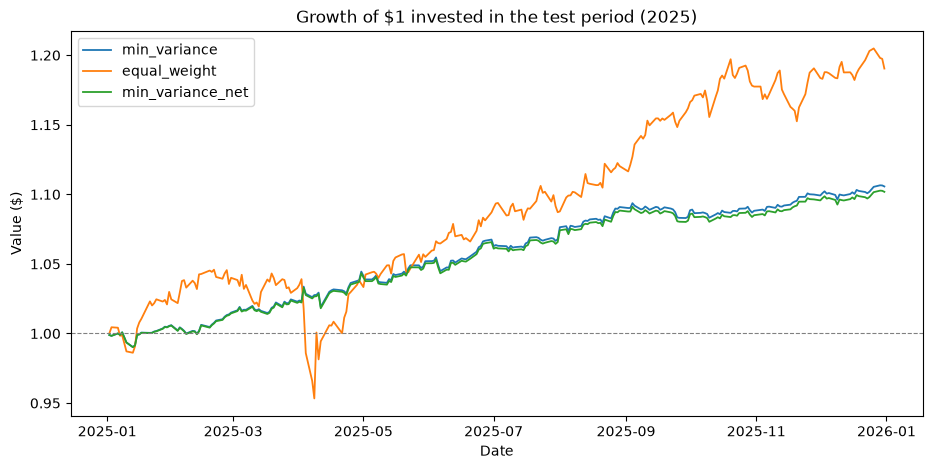

In [10]:
growth = np.exp(port_test.cumsum())

fig, ax = plt.subplots(figsize=(11, 5))
for name in growth.columns:
    ax.plot(growth.index, growth[name], label=name, linewidth=1.3)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_title(f"Growth of $1 invested in the test period ({TEST_START[:4]})")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend()
plt.show()

The chart shows the trade-off clearly: 1/N ends the year higher but with a much bumpier path, including a sharp fall during the spring sell-off (from 20 February to 8 April), while minimum variance grows slowly and steadily. The borrow fee barely separates the net and gross minimum-variance lines.

## 9. Robustness: other test years

A single test year can be misleading. We repeat the whole exercise for **2008** (financial crisis), **2020** (COVID crash) and **2022** (inflation and rate shock), each time re-estimating $\hat\Sigma$ on the previous years. 2020, 2022 and 2025 use 4 years of estimation; 2008 uses 3 (2005–2007), because the data starts in January 2005.

In [11]:
def evaluate_test_year(year, n_est_years=4):
    """Estimate on the n_est_years before `year`, test on `year`."""
    est_y = returns.loc[f"{year - n_est_years}-01-01":f"{year - 1}-12-31"]
    test_y = returns.loc[f"{year}-01-01":f"{year}-12-31"]

    Sigma_y = est_y.cov().to_numpy()
    a = min_variance_weights(Sigma_y)
    mv = performance(test_y @ a)
    ew = performance(test_y @ a_ew)

    return pd.Series({
        "mv_in_sample_vol": portfolio_volatility(a, Sigma_y),
        "mv_test_vol": mv["ann_volatility"],
        "ew_test_vol": ew["ann_volatility"],
        "mv_test_return": mv["ann_return"],
        "ew_test_return": ew["ann_return"],
        "mv_max_drawdown": mv["max_drawdown"],
        "ew_max_drawdown": ew["max_drawdown"],
        "mv_total_short": -a[a < 0].sum(),
    })


# Test year -> number of estimation years (2008 only has 3 years of data before it)
TEST_YEARS = {2008: 3, 2020: 4, 2022: 4, 2025: 4}

robustness = pd.DataFrame({year: evaluate_test_year(year, n) for year, n in TEST_YEARS.items()}).T
robustness.round(4)

,mv_in_sample_vol,mv_test_vol,ew_test_vol,mv_test_return,ew_test_return,mv_max_drawdown,ew_max_drawdown,mv_total_short
2008,0.0297,0.0968,0.2826,-0.0335,-0.2223,-0.1436,-0.3719,0.7183
2020,0.0229,0.0619,0.1968,0.0704,0.1242,-0.0740,-0.2246,0.5640
2022,0.0284,0.0763,0.1510,-0.0846,-0.2079,-0.1135,-0.2446,0.4736
2025,0.0533,0.0356,0.1061,0.1013,0.1757,-0.0141,-0.0885,0.7059


The table summarizes each year in a few numbers. The charts below show the full path of $1 invested in each strategy, with all four panels on the same vertical scale so the size of the falls can be compared directly.

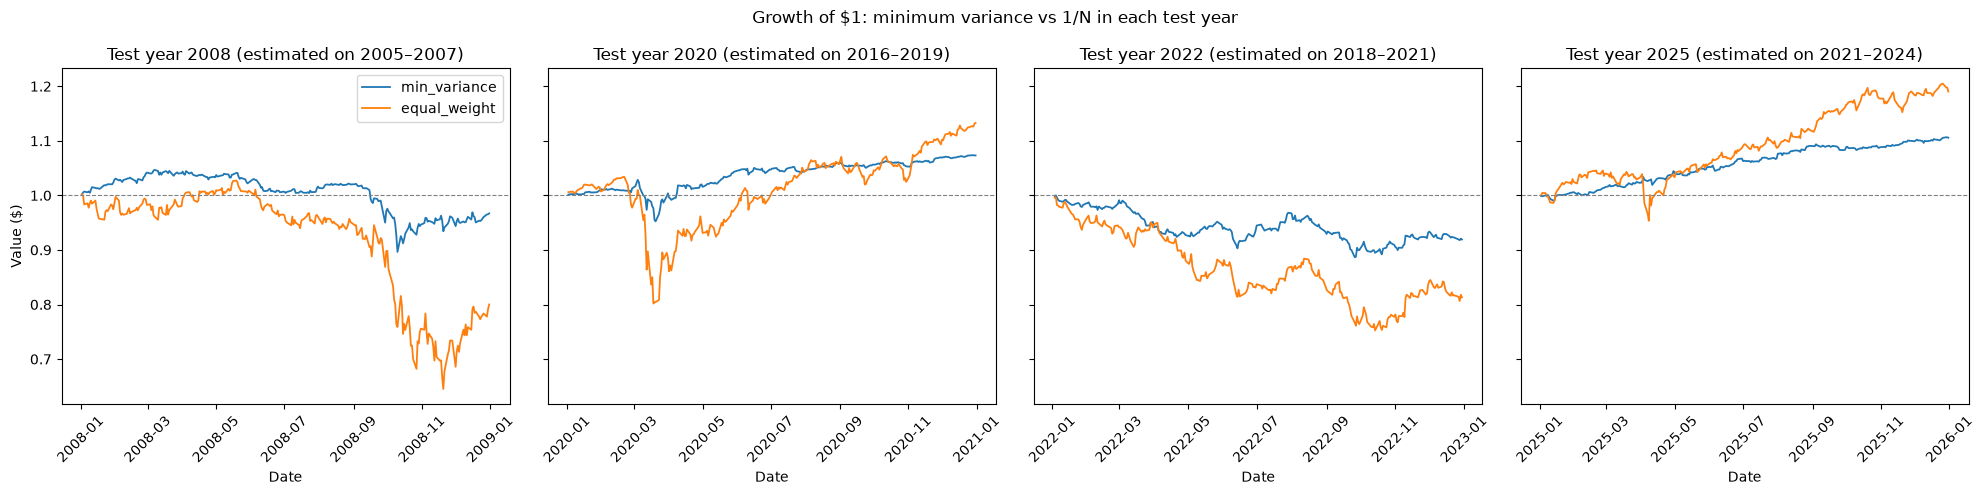

In [12]:
fig, axes = plt.subplots(1, len(TEST_YEARS), figsize=(20, 5), sharey=True)

for ax, (year, n) in zip(axes, TEST_YEARS.items()):
    est_y = returns.loc[f"{year - n}-01-01":f"{year - 1}-12-31"]
    test_y = returns.loc[f"{year}-01-01":f"{year}-12-31"]

    a = min_variance_weights(est_y.cov().to_numpy())
    growth_y = np.exp(pd.DataFrame({
        "min_variance": test_y @ a,
        "equal_weight": test_y @ a_ew,
    }).cumsum())

    for name in growth_y.columns:
        ax.plot(growth_y.index, growth_y[name], label=name, linewidth=1.3)
    ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
    ax.set_title(f"Test year {year} (estimated on {year - n}–{year - 1})")
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Value ($)")
axes[0].legend()
fig.suptitle("Growth of $1: minimum variance vs 1/N in each test year")
plt.tight_layout()
plt.show()

Across the four test years, minimum variance follows a much smoother path than 1/N. The difference is largest in the stress years: in 2008 it lost 3.4% while 1/N lost 22% (worst fall −14.4% vs −37.2%), in 2020 it avoided most of the COVID crash (−7.4% vs −22.5%), and in 2022 it lost less than half as much as 1/N (−8.5% vs −20.8%). In strong equity years such as 2020's recovery and 2025, the price of that stability is a lower final value.

**What protected the portfolio in 2008 was low equity exposure, not the Treasury pair.** Long Treasuries were the best hedge of 2008 (TLT gained 34%), but the portfolio was **short** TLT. Its long IEF position gained about +20 percentage points and its TLT short lost about −18, so the pair roughly cancelled out; most of the 3.4% loss came from its 24% position in SPY. The long-short Treasury pair reduces interest-rate risk in normal times, but it also gives up most of the flight-to-safety gains that make Treasuries valuable in a crisis.

**What changes and what doesn't**

- **Volatility ranking is stable:** minimum variance had lower volatility than 1/N in all four years (9.7% vs 28.3% in 2008, 6.2% vs 19.7% in 2020, 7.6% vs 15.1% in 2022, 3.6% vs 10.6% in 2025).
- **In-sample volatility is usually too optimistic.** The realized volatility was about **3.3 times** the in-sample estimate in 2008 (3.0% → 9.7%) and about **2.7 times** in 2020 and 2022 (2.3% → 6.2% and 2.8% → 7.6%). 2025 is the exception, not the rule.
- **Drawdowns were always smaller** for minimum variance (−14.4% vs −37.2% in 2008, −7.4% vs −22.5% in 2020, −11.4% vs −24.5% in 2022).
- **The return ranking depends on the year.** 1/N earned more in 2020 and 2025, while in 2008 and 2022 both lost money but minimum variance lost much less (−3.4% vs −22.2% and −8.5% vs −20.8%).
- **The structure of the weights is similar every year:** long IEF (116%–137%) and short TLT (−39% to −62%), with total short positions between 47% and 72%.

### Why minimum variance lost less: the weights and where the losses came from

The table shows the minimum-variance weights used in each test year, each one estimated only on the years before it.

In [13]:
weights_by_year = pd.DataFrame({
    year: min_variance_weights(
        returns.loc[f"{year - n}-01-01":f"{year - 1}-12-31"].cov().to_numpy()
    )
    for year, n in TEST_YEARS.items()
}, index=tickers)

weights_by_year.round(3)

,2008,2020,2022,2025
SPY,0.242,0.079,0.047,0.074
IWM,-0.052,0.013,0.008,-0.034
EFA,-0.020,0.017,0.044,-0.004
EEM,-0.022,-0.027,0.000,0.033
TLT,-0.619,-0.468,-0.387,-0.597
IEF,1.230,1.163,1.375,1.309
LQD,0.220,0.292,-0.029,0.290
GLD,0.026,-0.031,-0.029,-0.026
VNQ,-0.005,-0.037,-0.030,-0.044


To see **where** each portfolio gained or lost, we split its return over the year into one contribution per asset:

$$\text{contribution}_k = a_k \times r_k$$

where $a_k$ is the asset's weight and $r_k$ its (log) return over the year. Because our portfolio returns are computed as the weighted sum of the assets' log returns (`test @ a`), the contributions add up exactly to the portfolio's return for the year. (The totals can differ slightly from the robustness table, which annualizes the daily mean as mean × 252, while here we add up the year's actual trading days.) A negative weight on an asset that falls gives a **positive** contribution: that is the gain on a short position.

In [14]:
def contributions(year):
    """Contribution of each asset to the year's return, for minimum variance and for 1/N."""
    a = weights_by_year[year].to_numpy()
    asset_return = returns.loc[str(year)].sum()   # log return of each asset over the year
    table = pd.DataFrame({
        "mv_weight": a,
        "asset_return": asset_return,
        "mv_contribution": a * asset_return,
        "ew_contribution": a_ew * asset_return,
    }, index=tickers)
    table.loc["total"] = [a.sum(), np.nan, table["mv_contribution"].sum(), table["ew_contribution"].sum()]
    return table


print("2022 (inflation and rate shock)")
display(contributions(2022).round(4))
print("2008 (financial crisis)")
display(contributions(2008).round(4))

2022 (inflation and rate shock)


,mv_weight,asset_return,mv_contribution,ew_contribution
SPY,0.0472,-0.2006,-0.0095,-0.0223
IWM,0.0079,-0.2292,-0.0018,-0.0255
EFA,0.0437,-0.1553,-0.0068,-0.0173
EEM,0.0004,-0.2302,-0.0001,-0.0256
TLT,-0.3865,-0.3745,0.1447,-0.0416
IEF,1.3745,-0.1643,-0.2259,-0.0183
LQD,-0.0287,-0.1975,0.0057,-0.0219
GLD,-0.0285,-0.0078,0.0002,-0.0009
VNQ,-0.0299,-0.3045,0.0091,-0.0338
total,1.0000,NaN,-0.0843,-0.2071


2008 (financial crisis)


,mv_weight,asset_return,mv_contribution,ew_contribution
SPY,0.2423,-0.4588,-0.1112,-0.0510
IWM,-0.0520,-0.4177,0.0217,-0.0464
EFA,-0.0200,-0.5282,0.0106,-0.0587
EEM,-0.0217,-0.6710,0.0146,-0.0746
TLT,-0.6192,0.2923,-0.1810,0.0325
IEF,1.2302,0.1648,0.2028,0.0183
LQD,0.2201,0.0239,0.0053,0.0027
GLD,0.0257,0.0481,0.0012,0.0053
VNQ,-0.0053,-0.4618,0.0025,-0.0513
total,1.0000,NaN,-0.0336,-0.2231


**2022: how the hedge worked**

Minimum variance lost 8.4% in 2022, against 20.7% for 1/N. Splitting the loss by asset:

| Source | Calculation | Contribution |
|---|---|---|
| Long IEF | $1.375 \times (-16.4\%)$ | −22.6 pp |
| Short TLT | $-0.387 \times (-37.5\%)$ | +14.5 pp |
| **Treasury pair** | | **−8.1 pp** |
| Stocks (SPY, EFA, IWM, about 10% long) | | −1.8 pp |
| Shorts in VNQ and LQD (both fell 20%–30%) | | +1.5 pp |
| Gold and EEM | | ≈ 0 |
| **Total** | | **−8.4%** |

Three mechanisms explain why it lost less:

1. **It held very few volatile assets.** Stocks and REITs, which fell 15%–30% in 2022, had only about 10% of the portfolio combined (and VNQ was shorted). In 1/N they had 56% (five assets at 1/9 each), and they cost it about 12.5 percentage points.
2. **The Treasury pair cut its interest-rate risk.** IEF fell 16%, but the short in TLT, which fell more than twice as much (37%), offset about two thirds of that loss. Holding long intermediate bonds and shorting long bonds leaves much less net sensitivity to rates than holding bonds outright. 1/N had no such hedge: its 11% in TLT alone cost it 4.2 points.
3. **Small shorts in falling assets added a little.** The −3% positions in VNQ and LQD earned about 1.5 points.

**2008: a different source of protection**

Minimum variance lost 3.4% in 2008, against 22.3% for 1/N, but for a different reason. The Treasury pair roughly cancelled out (+20.3 points from IEF, −18.1 from the TLT short, as both rallied), so it neither helped nor hurt. The protection came from **low equity exposure**: SPY had 24% (−11.1 points), partly offset by small shorts in IWM, EFA and EEM (+4.7 points). 1/N, with 56% in stocks and REITs, lost about 28 points on them.

**The common thread.** Minimum variance does not predict crises. It simply builds the portfolio from $\hat\Sigma$ so that it holds little of the assets with high volatility and uses highly correlated pairs (IEF and TLT) to hedge each other. When a crash hits the volatile assets, there is little of them in the portfolio to lose. The price is the same in the other direction: in strong years for stocks, such as 2020's recovery and 2025, it also gains much less than 1/N.

## 10. Conclusions

1. **Volatility.** Minimum variance delivered lower out-of-sample volatility than 1/N in every test year: about 66% lower in 2008, 69% lower in 2020, 49% lower in 2022 and 66% lower in 2025. Compared with in-sample, the 2025 result (3.56% vs 5.33%) was unusually favorable; in 2008, 2020 and 2022 the realized volatility was about 2.7 to 3.3 times the in-sample estimate. In-sample volatility should be read as a lower bound, not a forecast.

2. **Returns.** Minimum variance makes no promise about returns, and 1/N earned more in the strong equity years (2020 and 2025). Minimum variance earned more per unit of risk in 2025 (return/vol 2.84 vs 1.66) and protected capital in the two crash years: −3.4% vs −22.2% in 2008 and −8.5% vs −20.8% in 2022.

3. **Relying on one test year.** The volatility and drawdown rankings held in all four years, but the size of the gap, the in-sample vs out-of-sample relationship and the return ranking all changed from year to year. Judging the strategy on 2025 alone would have overstated its out-of-sample precision. This motivates Part 3: a rolling-window backtest with monthly rebalancing, which evaluates the strategy over many periods instead of one.

4. **Short positions and costs.** The portfolio is heavily long-short: in 2025 it held 130.9% in IEF financed largely by a −59.7% position in TLT, for a total short of 70.6% (gross exposure of about 241%). At a 0.5% borrow fee this costs about 0.35% per year, and about 2.1% at a 3% fee. Beyond the fee, the strategy depends on the IEF–TLT relationship staying stable, requires margin, and, as 2008 showed, the TLT short gives up the crisis gains of long Treasuries. A **long-only** version (no short sales) is a natural next step to compare.